# Transferegov discricionárias e legais: extraction and fit, release 2026-07-17

Builds one proposal-grain evidence table from the nine Transferegov open-data CSVs: each proposal with its programme, recipient, instrument, stage dates and stage amounts kept separate. Source, access and rules: the review README and `methodology.md` one level up; need `2026-09-br-finance-pathways-review`. Raws live in `sample/` (gitignored, re-download steps in the README), and the output table is written to `sample/` too, because at about 1.15 million rows it is too large to commit.

In [1]:
# Parameters
from pathlib import Path
SAMPLE = Path("sample")
RAW = {name: SAMPLE / f"siconv_{name}.csv.zip" for name in
       ["programa", "programa_proposta", "proposta", "convenio", "empenho", "desembolso", "pagamento", "historico_situacao"]}
OUT = SAMPLE / "br_transferegov_proposals_2026-07-17.csv.gz"   # gitignored working output (too large to commit)
SNAPSHOT = "2026-07-17"          # export date; latest events in the files are 16 July 2026
VALID_FROM = "2008-01-01"        # SICONV start; earlier event dates are migrated legacy or typos
CITY_APPLICANTS = ["Administração Pública Municipal", "Consórcio Público"]

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print(f"snapshot {SNAPSHOT}; {sum(p.exists() for p in RAW.values())}/{len(RAW)} raw files present")

snapshot 2026-07-17; 8/8 raw files present


## Load raw

Zero transformations: every file is read as text, semicolon-delimited, UTF-8 with BOM, blanks as null. Column selection is the only exception and it is where personal and sensitive data is dropped (parsing note PN2): supplier identifier and name in `pagamento`, and the applicant's street address, postcode, district, bank, branch and account in `proposta`. Free-text notes on commitments and disbursements are not loaded because nothing downstream uses them and they can name people.

In [2]:
# Load helper: all columns as text, blank -> null (parsing note PN1)
# Low-cardinality label columns are read as categories: still the raw text, at a fraction of the memory.
def read_raw(name, usecols=None, categories=()):
    dtype = {c: ("category" if c in categories else str) for c in usecols} if usecols else str
    return pd.read_csv(RAW[name], sep=";", dtype=dtype, encoding="utf-8-sig",
                       keep_default_na=False, na_values=[""], usecols=usecols)

In [3]:
# Load raw: programme master (one row per programme x state; parsing note PN5)
raw_programa = read_raw("programa", usecols=[
    "ID_PROGRAMA", "COD_PROGRAMA", "NOME_PROGRAMA", "DESC_ORGAO_SUP_PROGRAMA", "SIT_PROGRAMA",
    "ANO_DISPONIBILIZACAO", "MODALIDADE_PROGRAMA", "ACAO_ORCAMENTARIA", "NOME_SUBTIPO_PROGRAMA", "UF_PROGRAMA"])
raw_programa.shape

(1255214, 10)

In [4]:
# Load raw: programme-proposal bridge
raw_bridge = read_raw("programa_proposta")
raw_bridge.shape

(1155057, 2)

In [5]:
# Load raw: proposals. PN2: applicant address, postcode, district, bank and account columns are not loaded.
PROPOSTA_COLS = [
    "ID_PROPOSTA", "NR_PROPOSTA", "UF_PROPONENTE", "MUNIC_PROPONENTE", "COD_MUNIC_IBGE", "NATUREZA_JURIDICA",
    "IDENTIF_PROPONENTE", "NM_PROPONENTE", "DESC_ORGAO_SUP", "DESC_ORGAO", "MODALIDADE", "SIT_PROPOSTA",
    "DIA_PROPOSTA", "OBJETO_PROPOSTA", "ITEM_INVESTIMENTO", "ENVIADA_MANDATARIA", "NOME_SUBTIPO_PROPOSTA",
    "VL_GLOBAL_PROP", "VL_REPASSE_PROP", "VL_CONTRAPARTIDA_PROP"]
raw_proposta = read_raw("proposta", usecols=PROPOSTA_COLS)
raw_proposta.shape

(1153701, 20)

In [6]:
# Load raw: agreements (instruments)
raw_convenio = read_raw("convenio", usecols=[
    "NR_CONVENIO", "ID_PROPOSTA", "DIA_ASSIN_CONV", "SIT_CONVENIO", "SITUACAO_CONTRATACAO", "IND_ASSINADO",
    "INSTRUMENTO_ATIVO", "IND_OPERA_OBTV", "VL_EMPENHADO_CONV", "VL_DESEMBOLSADO_CONV",
    "VL_GLOBAL_CONV", "VL_REPASSE_CONV", "VL_CONTRAPARTIDA_CONV"])
raw_convenio.shape

(285743, 13)

In [7]:
# Load raw: budget-commitment events (free-text note not loaded)
raw_empenho = read_raw("empenho", usecols=["ID_EMPENHO", "NR_CONVENIO", "DESC_TIPO_NOTA", "DATA_EMISSAO", "VALOR_EMPENHO"])
raw_empenho.shape

(434899, 5)

In [8]:
# Load raw: disbursements to the instrument account (free-text note not loaded)
raw_desembolso = read_raw("desembolso", usecols=["ID_DESEMBOLSO", "NR_CONVENIO", "DATA_DESEMBOLSO", "VL_DESEMBOLSADO"])
raw_desembolso.shape

(378212, 4)

In [9]:
# Load raw: onward payments. PN2: IDENTIF_FORNECEDOR and NOME_FORNECEDOR are never loaded.
raw_pagamento = read_raw("pagamento", usecols=["NR_CONVENIO", "TP_MOV_FINANCEIRA", "DESC_DL", "DATA_PAG", "VL_PAGO"],
                         categories=("TP_MOV_FINANCEIRA", "DESC_DL"))
raw_pagamento.shape

(7359136, 5)

In [10]:
# Load raw: proposal and agreement status history
raw_historico = read_raw("historico_situacao", usecols=["ID_PROPOSTA", "NR_CONVENIO", "DIA_HISTORICO_SIT", "HISTORICO_SIT", "COD_HISTORICO_SIT"],
                         categories=("HISTORICO_SIT", "COD_HISTORICO_SIT"))
raw_historico.shape

(8957864, 5)

## Clean

One block per README parsing note (PN1 to PN11). Amounts are handled in integer centavos from here on so that sums are exact.

In [11]:
# Clean helpers. PN3: amounts use a decimal comma (no thousands separator); some agreement totals carry
# floating-point residues printed in scientific notation (e.g. -5,82e-11). Converting to integer centavos
# rounds residues to zero and makes every later sum exact.
def to_centavos(s):
    reais = pd.to_numeric(s.str.replace(",", ".", regex=False), errors="raise")
    return (reais * 100).round().astype("Int64")

# PN4: dates are dd/mm/yyyy (history adds hh:mm:ss). Impossible years (0010, 0016, 1900, 3012...) exist.
# Out-of-window dates become null and are counted, never silently parsed.
def to_event_date(s, fmt="%d/%m/%Y"):
    d = pd.to_datetime(s, format=fmt, errors="coerce")
    return d.where(d.between(VALID_FROM, SNAPSHOT))

def invalid_dates(raw, parsed):
    return int((raw.notna() & parsed.isna()).sum())
print("helpers ready")

helpers ready


In [12]:
# Clean: programme master to one row per programme (PN5: rows repeat per state, applicant legal nature and
# offered modality; only MODALIDADE_PROGRAMA varies within an ID, so it is dropped here and the instrument
# is taken from the proposal's own MODALIDADE)
programa = raw_programa.drop(columns=["UF_PROGRAMA", "MODALIDADE_PROGRAMA"]).drop_duplicates()
assert programa["ID_PROGRAMA"].is_unique
{"raw_rows": len(raw_programa), "programmes": len(programa)}

{'raw_rows': 1255214, 'programmes': 52935}

In [13]:
# Clean: one primary programme per proposal (PN6: 1,231 proposals link to more than one programme;
# primary = lowest ID_PROGRAMA, the count is kept so multi-programme proposals stay visible)
bridge = raw_bridge.assign(id_programa_num=raw_bridge["ID_PROGRAMA"].astype(int)).sort_values("id_programa_num")
prog_link = (bridge.groupby("ID_PROPOSTA")
             .agg(id_programa=("ID_PROGRAMA", "first"), n_programas=("ID_PROGRAMA", "nunique"))
             .reset_index())
prog_link = prog_link.merge(
    programa.rename(columns={"ID_PROGRAMA": "id_programa", "COD_PROGRAMA": "cod_programa", "NOME_PROGRAMA": "nome_programa",
                             "DESC_ORGAO_SUP_PROGRAMA": "orgao_programa", "ACAO_ORCAMENTARIA": "acao_orcamentaria",
                             "NOME_SUBTIPO_PROGRAMA": "subtipo_programa"})
    [["id_programa", "cod_programa", "nome_programa", "orgao_programa", "acao_orcamentaria", "subtipo_programa"]],
    on="id_programa", how="left", validate="m:1")
prog_link["n_programas"].value_counts().head()

n_programas
1    1152395
2       1106
3         94
4         16
5          7
Name: count, dtype: int64

In [14]:
# Clean: proposals typed (PN3 amounts, PN4 dates, PN8 IBGE code as 7-character text key)
proposta = pd.DataFrame({
    "id_proposta": raw_proposta["ID_PROPOSTA"],
    "nr_proposta": raw_proposta["NR_PROPOSTA"],
    "uf": raw_proposta["UF_PROPONENTE"],
    "municipio": raw_proposta["MUNIC_PROPONENTE"],
    "cod_ibge": raw_proposta["COD_MUNIC_IBGE"].str.strip(),
    "natureza_juridica": raw_proposta["NATUREZA_JURIDICA"],
    "cnpj_proponente": raw_proposta["IDENTIF_PROPONENTE"],      # always a 14-digit CNPJ: organisations, not people
    "nome_proponente": raw_proposta["NM_PROPONENTE"],
    "orgao_superior": raw_proposta["DESC_ORGAO_SUP"],
    "orgao_concedente": raw_proposta["DESC_ORGAO"],
    "modalidade": raw_proposta["MODALIDADE"],
    "sit_proposta": raw_proposta["SIT_PROPOSTA"],
    "subtipo_proposta": raw_proposta["NOME_SUBTIPO_PROPOSTA"],
    "enviada_mandataria": raw_proposta["ENVIADA_MANDATARIA"],
    "item_investimento": raw_proposta["ITEM_INVESTIMENTO"],
    "objeto_proposta": raw_proposta["OBJETO_PROPOSTA"],
    "dt_proposta": to_event_date(raw_proposta["DIA_PROPOSTA"]),
    "vl_global_prop_cent": to_centavos(raw_proposta["VL_GLOBAL_PROP"]),
    "vl_repasse_prop_cent": to_centavos(raw_proposta["VL_REPASSE_PROP"]),
    "vl_contrapartida_prop_cent": to_centavos(raw_proposta["VL_CONTRAPARTIDA_PROP"]),
})
{"rows": len(proposta), "invalid_dt_proposta": invalid_dates(raw_proposta["DIA_PROPOSTA"], proposta["dt_proposta"])}

{'rows': 1153701, 'invalid_dt_proposta': 0}

In [15]:
# Clean: agreements typed (PN3, PN4). PN9: IND_ASSINADO = SIM exactly where a signature date exists.
convenio = pd.DataFrame({
    "nr_convenio": raw_convenio["NR_CONVENIO"],
    "id_proposta": raw_convenio["ID_PROPOSTA"],
    "sit_convenio": raw_convenio["SIT_CONVENIO"],
    "situacao_contratacao": raw_convenio["SITUACAO_CONTRATACAO"],
    "is_signed": raw_convenio["IND_ASSINADO"].eq("SIM"),
    "is_active_instrument": raw_convenio["INSTRUMENTO_ATIVO"].eq("SIM"),
    "operates_obtv": raw_convenio["IND_OPERA_OBTV"].eq("SIM"),
    "dt_assinatura": to_event_date(raw_convenio["DIA_ASSIN_CONV"]),
    "vl_global_conv_cent": to_centavos(raw_convenio["VL_GLOBAL_CONV"]),
    "vl_repasse_conv_cent": to_centavos(raw_convenio["VL_REPASSE_CONV"]),
    "vl_contrapartida_conv_cent": to_centavos(raw_convenio["VL_CONTRAPARTIDA_CONV"]),
})
pd.crosstab(convenio["is_signed"], convenio["dt_assinatura"].notna(), rownames=["is_signed"], colnames=["has_signature_date"])

has_signature_date,False,True
is_signed,,
False,50118,0
True,0,235625


In [16]:
# Clean: status labels to administrative stage families (methodology.md, "Financial and administrative signals").
# PN7: COD_HISTORICO_SIT = -1 marks labels that have no numeric code (PRESTACAO_CONTAS_CONCLUIDA,
# ..._COMPROVADA_EM_ANALISE, RASCUNHO, PLANO_TRABALHO_ENVIADO_ANALISE), so the text label is authoritative.
STAGE_FAMILIES = {
    "submitted": ["PROPOSTA_ENVIADA_ANALISE", "PROPOSTA_COMPLEMENTADA_ENVIADA_ANALISE",
                  "EM_CHAMAMENTO_PUBLICO_ENVIADA_PARA_ANALISE_PRELIMINAR"],
    "approved": ["PLANO_TRABALHO_APROVADO", "PROPOSTA_APROVADA_AGUARDANDO_PLANO_TRABALHO"],
    "rejected": ["PROPOSTA_REPROVADA", "PROPOSTA_REJEITADA_IMPEDIMENTO_TECNICO",
                 "PROPOSTA_ELIMINADA_EM_CHAMAMENTO_PUBLICO", "EM_CHAMAMENTO_PUBLICO_ELIMINADA_ANALISE_PRELIMINAR"],
    "signed_event": ["ASSINADA"],
    "annulled_or_rescinded": ["CONVENIO_ANULADO", "CONVENIO_RESCINDIDO", "PROPOSTA_CANCELADA"],
}
label_to_family = {label: fam for fam, labels in STAGE_FAMILIES.items() for label in labels}
stage_events = raw_historico.loc[raw_historico["HISTORICO_SIT"].isin(label_to_family),
                                 ["ID_PROPOSTA", "DIA_HISTORICO_SIT", "HISTORICO_SIT"]].copy()
stage_events["family"] = stage_events["HISTORICO_SIT"].astype(str).map(label_to_family)
stage_events.groupby("family").size().to_frame("events")

,events
family,
annulled_or_rescinded,30793
approved,746811
rejected,287336
signed_event,364153
submitted,1497657


In [17]:
# Clean: first date of each stage family per proposal. PN7: repeated events (same proposal, label and timestamp)
# do not affect a first date, so they are not deduplicated. PN4: pre-2008 dates (4 migrated rows) become null.
stage_events["dt_evento"] = to_event_date(stage_events["DIA_HISTORICO_SIT"], fmt="%d/%m/%Y %H:%M:%S")
first_stage = (stage_events.dropna(subset=["dt_evento"]).groupby(["ID_PROPOSTA", "family"])["dt_evento"].min()
               .unstack("family").add_prefix("dt_first_").reset_index().rename(columns={"ID_PROPOSTA": "id_proposta"}))
first_stage.rename_axis(columns=None, inplace=True)
{"invalid_dates": invalid_dates(stage_events["DIA_HISTORICO_SIT"], stage_events["dt_evento"]),
 **first_stage.drop(columns="id_proposta").notna().sum().to_dict()}

{'invalid_dates': 4,
 'dt_first_annulled_or_rescinded': 25816,
 'dt_first_approved': 279114,
 'dt_first_rejected': 253634,
 'dt_first_signed_event': 234909,
 'dt_first_submitted': 877436}

In [18]:
# Clean: net commitment per agreement (PN10: sign comes from VALOR_EMPENHO, never from the description;
# ID_EMPENHO is not a global key; 4 events with blank NR_CONVENIO cannot be attributed and are excluded)
empenho = raw_empenho.dropna(subset=["NR_CONVENIO"]).assign(
    valor_cent=lambda d: to_centavos(d["VALOR_EMPENHO"]),
    positive_cent=lambda d: d["valor_cent"].clip(lower=0),
    dt_emissao=lambda d: to_event_date(d["DATA_EMISSAO"]))
emp_agg = (empenho.groupby("NR_CONVENIO")
           .agg(vl_empenho_net_cent=("valor_cent", "sum"),
                vl_empenho_gross_pos_cent=("positive_cent", "sum"),
                dt_first_empenho=("dt_emissao", "min"), n_empenho_events=("valor_cent", "size"))
           .reset_index().rename(columns={"NR_CONVENIO": "nr_convenio"}))
{"agreements_with_events": len(emp_agg), "blank_agreement_events_excluded": len(raw_empenho) - len(empenho),
 "invalid_event_dates": invalid_dates(empenho["DATA_EMISSAO"], empenho["dt_emissao"])}

{'agreements_with_events': 272291,
 'blank_agreement_events_excluded': 4,
 'invalid_event_dates': 1754}

In [19]:
# Clean: disbursements per agreement (PN3, PN4; negative rows stay in the net)
desembolso = raw_desembolso.assign(valor_cent=lambda d: to_centavos(d["VL_DESEMBOLSADO"]),
                                   dt=lambda d: to_event_date(d["DATA_DESEMBOLSO"]),
                                   dt_positive=lambda d: d["dt"].where(d["valor_cent"] > 0))
des_agg = (desembolso.groupby("NR_CONVENIO")
           .agg(vl_desembolso_net_cent=("valor_cent", "sum"),
                dt_first_desembolso=("dt_positive", "min"),
                n_desembolsos=("valor_cent", "size"))
           .reset_index().rename(columns={"NR_CONVENIO": "nr_convenio"}))
{"agreements_with_disbursement_rows": len(des_agg), "invalid_dates": invalid_dates(desembolso["DATA_DESEMBOLSO"], desembolso["dt"])}

{'agreements_with_disbursement_rows': 187286, 'invalid_dates': 1}

In [20]:
# Clean: onward payments per agreement. PN11: document type "OBTV PARA O CONVENENTE" moves money from the
# instrument account back to the recipient itself; it is kept apart from payments to suppliers and other creditors.
# Zero-value rows carry no movement; negative rows (reversals) stay in the net.
pagamento = raw_pagamento.assign(valor_cent=lambda d: to_centavos(d["VL_PAGO"]),
                                 dt=lambda d: to_event_date(d["DATA_PAG"]),
                                 to_recipient=lambda d: d["DESC_DL"].astype(str).eq("OBTV PARA O CONVENENTE"))
onward = pagamento.loc[~pagamento["to_recipient"] & pagamento["valor_cent"].ne(0)]
pag_agg = (onward.groupby("NR_CONVENIO")
           .agg(vl_pago_net_cent=("valor_cent", "sum"), dt_first_pagamento=("dt", "min"), n_pagamentos=("valor_cent", "size"))
           .join(pagamento.loc[pagamento["to_recipient"]].groupby("NR_CONVENIO")["valor_cent"].sum()
                 .rename("vl_pago_convenente_net_cent"), how="outer")
           .reset_index().rename(columns={"NR_CONVENIO": "nr_convenio"}))
{"agreements_with_onward_payments": int(pag_agg["vl_pago_net_cent"].notna().sum()),
 "to_recipient_rows": int(pagamento["to_recipient"].sum()), "zero_rows_skipped": int(pagamento["valor_cent"].eq(0).sum()),
 "invalid_dates": invalid_dates(pagamento["DATA_PAG"], pagamento["dt"])}

{'agreements_with_onward_payments': 170102,
 'to_recipient_rows': 357195,
 'zero_rows_skipped': 25420,
 'invalid_dates': 34}

## Assemble

Proposal grain: one row per `ID_PROPOSTA`. Each proposal has at most one agreement, so agreement-level stage amounts attach without fan-out. Stage flags are derived here; amounts from different stages stay in separate columns and are never added together.

In [21]:
# Assemble: proposal + programme + agreement + stage aggregates
agreement = (convenio.merge(emp_agg, on="nr_convenio", how="left", validate="1:1")
                     .merge(des_agg, on="nr_convenio", how="left", validate="1:1")
                     .merge(pag_agg, on="nr_convenio", how="left", validate="1:1"))
proposals = (proposta.merge(prog_link.rename(columns={"ID_PROPOSTA": "id_proposta"}), on="id_proposta", how="left", validate="1:1")
                     .merge(first_stage, on="id_proposta", how="left", validate="1:1")
                     .merge(agreement, on="id_proposta", how="left", validate="1:1"))
for col in ["n_programas", "n_empenho_events", "n_desembolsos", "n_pagamentos"]:
    proposals[col] = proposals[col].fillna(0).astype(int)
proposals.shape

(1153701, 53)

In [22]:
# Derive: stage flags (methodology.md signal table). Not forced into one ordinal score.
cent = lambda c: proposals[c].fillna(0)
proposals["is_city_applicant"] = proposals["natureza_juridica"].isin(CITY_APPLICANTS) & proposals["cod_ibge"].str.fullmatch(r"\d{7}").fillna(False)
proposals["has_agreement"] = proposals["nr_convenio"].notna()
proposals["is_signed"] = proposals["is_signed"].fillna(False).astype(bool)
proposals["is_submitted"] = proposals["dt_first_submitted"].notna()
proposals["is_approved"] = proposals["dt_first_approved"].notna()
proposals["is_ever_committed"] = cent("vl_empenho_gross_pos_cent") > 0
proposals["is_net_committed"] = cent("vl_empenho_net_cent") > 0
proposals["is_disbursed"] = cent("vl_desembolso_net_cent") > 0
proposals["is_paid"] = cent("vl_pago_net_cent") > 0
proposals["submission_year"] = proposals["dt_first_submitted"].dt.year.astype("Int64")
FLAGS = ["is_submitted", "is_approved", "has_agreement", "is_signed", "is_ever_committed", "is_net_committed", "is_disbursed", "is_paid"]
proposals[FLAGS].sum().to_frame("proposals")

,proposals
is_submitted,877433
is_approved,279114
has_agreement,285743
is_signed,235625
is_ever_committed,255135
is_net_committed,215073
is_disbursed,187286
is_paid,170099


In [23]:
# Derive: quality flags for the known stage-order exceptions (retained and flagged, never repaired)
proposals["qf_committed_unsigned"] = proposals["is_net_committed"] & ~proposals["is_signed"]
proposals["qf_disbursed_no_net_commitment"] = proposals["is_disbursed"] & ~proposals["is_net_committed"]
proposals["qf_paid_no_disbursement"] = proposals["is_paid"] & ~proposals["is_disbursed"]
proposals["qf_negative_value"] = (proposals[["vl_global_prop_cent", "vl_contrapartida_prop_cent", "vl_global_conv_cent",
                                             "vl_repasse_conv_cent", "vl_contrapartida_conv_cent"]] < 0).any(axis=1)
QF = [c for c in proposals.columns if c.startswith("qf_")]
proposals[QF].sum().to_frame("proposals")

,proposals
qf_committed_unsigned,12474
qf_disbursed_no_net_commitment,7211
qf_paid_no_disbursement,246
qf_negative_value,2


## Validate

Assertions pinned to the Step 2 profile in the README. Known source-side defects are asserted as named counts. If anything fails, nothing is exported.

In [24]:
# Validate: raw row counts match the profiled snapshot (README profile table)
EXPECTED_ROWS = {"programa": 1_255_214, "programa_proposta": 1_155_057, "proposta": 1_153_701, "convenio": 285_743,
                 "empenho": 434_899, "desembolso": 378_212, "pagamento": 7_359_136, "historico_situacao": 8_957_864}
actual = {"programa": len(raw_programa), "programa_proposta": len(raw_bridge), "proposta": len(raw_proposta),
          "convenio": len(raw_convenio), "empenho": len(raw_empenho), "desembolso": len(raw_desembolso),
          "pagamento": len(raw_pagamento), "historico_situacao": len(raw_historico)}
assert actual == EXPECTED_ROWS, {k: (actual[k], v) for k, v in EXPECTED_ROWS.items() if actual[k] != v}
print("raw row counts match the profile")

raw row counts match the profile


In [25]:
# Validate: keys, grain and joins
assert proposals["id_proposta"].is_unique and len(proposals) == EXPECTED_ROWS["proposta"]
assert convenio["nr_convenio"].is_unique and convenio["id_proposta"].is_unique
assert convenio["id_proposta"].isin(proposta["id_proposta"]).all()                  # every agreement links to a proposal
assert proposals["has_agreement"].sum() == EXPECTED_ROWS["convenio"]
for name, agg in {"empenho": emp_agg, "desembolso": des_agg, "pagamento": pag_agg}.items():
    assert agg["nr_convenio"].isin(convenio["nr_convenio"]).all(), name              # every stage event resolves
assert len(programa) == 52_935
assert proposals["id_programa"].isna().sum() == 78                                    # proposals with no programme link
assert (proposals["n_programas"] > 1).sum() == 1_231
print("keys and joins valid")

keys and joins valid


In [26]:
# Validate: no personal data columns leaked into the output
PII_COLS = {"IDENTIF_FORNECEDOR", "NOME_FORNECEDOR", "ENDERECO_PROPONENTE", "CEP_PROPONENTE", "BAIRRO_PROPONENTE",
            "NM_BANCO", "CD_AGENCIA", "CD_CONTA", "OBSERVACAO_EMPENHO", "OBSERVACAO_DH"}
assert not PII_COLS & {c.upper() for c in proposals.columns}
assert proposals["cnpj_proponente"].str.fullmatch(r"\d{14}").all()                  # organisations only, never CPF
print("no personal-data columns in output")

no personal-data columns in output


In [27]:
# Validate: pinned source facts and named exceptions (README warnings and methodology signal table)
assert (convenio["is_signed"] == convenio["dt_assinatura"].notna()).all()             # PN9
assert (raw_empenho["VALOR_EMPENHO"].str.startswith("-")).sum() == 69_715
assert pagamento["valor_cent"].eq(0).sum() == 25_420 and pagamento["valor_cent"].lt(0).sum() == 27
assert (raw_historico["COD_HISTORICO_SIT"] == "-1").sum() == 217_770
# The 32 "negative committed values" in the profile: 16 are floating-point residues below one centavo (PN3),
# 16 are genuine negative totals that equal the agreement's own commitment-event net (cancellations recorded
# without the original commitment in the export)
neg_emp_conv = to_centavos(raw_convenio["VL_EMPENHADO_CONV"].dropna().loc[lambda s: s.str.startswith("-")])
assert len(neg_emp_conv) == 32 and neg_emp_conv.eq(0).sum() == 16
assert proposals["natureza_juridica"].eq("Administração Pública Municipal").sum() == 1_008_381
# Stage-order exceptions, counted in exact centavos. Earlier float-based profiling reported 12,511 / 7,210;
# float residues around 1e-10 had been counted as positive nets (see README, PN3). Paid-without-disbursement is
# 246 rather than the profiled 251 because payments back to the recipient itself (PN11) no longer count as paid.
NAMED_EXCEPTIONS = {"qf_committed_unsigned": 12_474, "qf_disbursed_no_net_commitment": 7_211, "qf_paid_no_disbursement": 246}
got = {k: int(proposals[k].sum()) for k in NAMED_EXCEPTIONS}
assert got == NAMED_EXCEPTIONS, got
assert not ((proposals["is_disbursed"] | proposals["is_paid"]) & ~proposals["is_signed"]).any()   # money only moves on signed instruments
print("pinned facts and named exceptions hold")

pinned facts and named exceptions hold


In [28]:
# Validate: stage totals reconcile exactly with the raw files (no rows lost or duplicated in aggregation)
assert proposals["vl_desembolso_net_cent"].sum() == desembolso["valor_cent"].sum()
assert proposals["vl_empenho_net_cent"].sum() == empenho["valor_cent"].sum()
assert proposals["vl_pago_net_cent"].sum() + proposals["vl_pago_convenente_net_cent"].sum() == pagamento["valor_cent"].sum()
# Cross-file check: event nets against the agreement table's own totals. Disbursement reconciles exactly;
# commitment differs for a named set of agreements (the agreement total is a separate, not always updated, field).
conv_totals = raw_convenio.set_index("NR_CONVENIO")[["VL_EMPENHADO_CONV", "VL_DESEMBOLSADO_CONV"]].apply(to_centavos).fillna(0)
by_conv = proposals.dropna(subset=["nr_convenio"]).set_index("nr_convenio")
assert (by_conv["vl_desembolso_net_cent"].fillna(0) == conv_totals["VL_DESEMBOLSADO_CONV"].reindex(by_conv.index)).all()
assert (by_conv["vl_empenho_net_cent"].fillna(0) != conv_totals["VL_EMPENHADO_CONV"].reindex(by_conv.index)).sum() == 7_833
brl = lambda c: proposals[c].sum() / 100 / 1e9
pd.Series({"net committed": brl("vl_empenho_net_cent"), "net disbursed": brl("vl_desembolso_net_cent"),
           "net paid onward": brl("vl_pago_net_cent")}, name="R$ billion, nominal").round(1).to_frame()

,"R$ billion, nominal"
net committed,193.6
net disbursed,150.2
net paid onward,121.9


In [29]:
# Release raw and intermediate frames: everything downstream reads only `proposals` (keeps peak memory near 4 GB)
del raw_programa, raw_bridge, raw_proposta, raw_convenio, raw_empenho, raw_desembolso, raw_pagamento, raw_historico
del proposta, convenio, empenho, desembolso, pagamento, onward, stage_events, agreement
import gc; gc.collect()
print(f"proposals in memory: {proposals.memory_usage(deep=True).sum() / 1e9:.2f} GB")

proposals in memory: 1.22 GB


## Export

One proposal-grain table. At about 1.15 million rows with the free-text object it is too large to commit, so it is written to `sample/` (gitignored) as a working output; re-running this notebook from the raws regenerates it.

In [30]:
# Export: proposal-grain evidence table (gitignored working output)
EXPORT_COLS = [
    "id_proposta", "nr_proposta", "nr_convenio", "uf", "cod_ibge", "municipio", "natureza_juridica", "is_city_applicant",
    "cnpj_proponente", "nome_proponente", "orgao_superior", "orgao_concedente", "id_programa", "cod_programa", "nome_programa",
    "orgao_programa", "acao_orcamentaria", "subtipo_programa", "n_programas", "subtipo_proposta", "modalidade",
    "enviada_mandataria", "item_investimento", "objeto_proposta", "sit_proposta", "sit_convenio", "situacao_contratacao",
    "dt_proposta", "dt_first_submitted", "dt_first_approved", "dt_first_rejected", "dt_first_signed_event", "dt_assinatura",
    "dt_first_empenho", "dt_first_desembolso", "dt_first_pagamento", "dt_first_annulled_or_rescinded", "submission_year",
    *FLAGS, "is_active_instrument", "operates_obtv",
    "vl_global_prop_cent", "vl_repasse_prop_cent", "vl_contrapartida_prop_cent",
    "vl_global_conv_cent", "vl_repasse_conv_cent", "vl_contrapartida_conv_cent",
    "vl_empenho_net_cent", "vl_empenho_gross_pos_cent", "vl_desembolso_net_cent", "vl_pago_net_cent", "vl_pago_convenente_net_cent",
    "n_empenho_events", "n_desembolsos", "n_pagamentos", *QF]
proposals[EXPORT_COLS].to_csv(OUT, index=False, date_format="%Y-%m-%d")
print(OUT, proposals[EXPORT_COLS].shape)

sample/br_transferegov_proposals_2026-07-17.csv.gz (1153701, 66)


## Visualise and fit

Aggregates the review cites, rendered here only. The fit cells answer what the need and the working methodology leave open: (1) how far city proposals travel through the stages, (2) how long follow-up must be before a cohort can be compared (the methodology's unanswered minimum window), (3) whether the need's must-have fields are present, and (4) what the stages look like around the 2019 and 2023 federal government transitions, plus the need's Novo PAC tracing test. The population is city applicants: municipal governments and public consortia with a valid IBGE code.

In [31]:
# Chart style: recessive grid, reference palette slots in fixed order
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "font.size": 10,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
FIT_COLS = ["id_proposta", "submission_year", "nome_proponente", "natureza_juridica", "uf", "cod_ibge", "nome_programa",
            "modalidade", "objeto_proposta", "vl_repasse_prop_cent", "dt_first_submitted", "dt_assinatura",
            "dt_first_desembolso", "dt_first_pagamento", *FLAGS]
city = proposals.loc[proposals["is_city_applicant"] & proposals["is_submitted"], FIT_COLS]
{"city proposals submitted": len(city), "city proposals never submitted (drafts)":
 int((proposals["is_city_applicant"] & ~proposals["is_submitted"]).sum())}

{'city proposals submitted': 791928,
 'city proposals never submitted (drafts)': 220060}

In [32]:
# Coverage: share of city proposals with a usable submission event, by proposal year. The status history's
# submission events begin in April 2010, so 2008-2009 proposals (migrated records) cannot enter the cohorts.
all_city = proposals.loc[proposals["is_city_applicant"], ["dt_proposta", "is_submitted", "is_signed"]]
coverage = all_city.groupby(all_city["dt_proposta"].dt.year).agg(
    proposals=("is_submitted", "size"), with_submission_event=("is_submitted", "mean"), signed=("is_signed", "mean"))
coverage.index.name = "proposal_year"
coverage.assign(with_submission_event=(coverage["with_submission_event"] * 100).round(1), signed=(coverage["signed"] * 100).round(1))

,proposals,with_submission_event,signed
proposal_year,,,
2008,21814,0.4,4.3
2009,110839,0.9,15.2
2010,86621,62.6,17.6
2011,64445,91.3,13.5
2012,43374,93.1,15.7
2013,84687,90.3,14.5
2014,47874,92.8,16.9
2015,44182,93.0,13.2
2016,31009,94.3,29.8


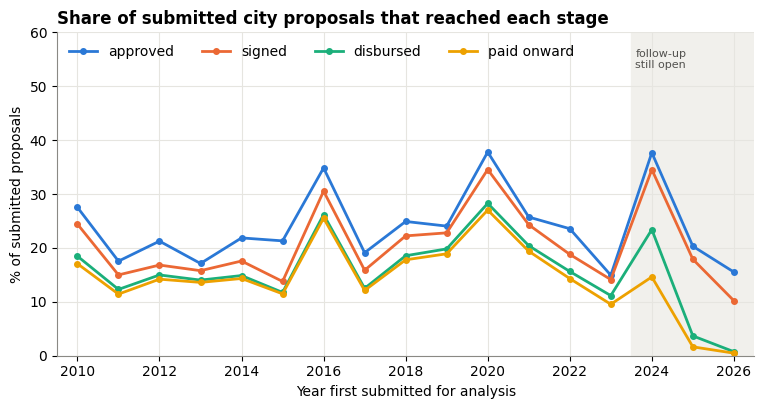

,submitted,approved,signed,disbursed,paid onward
submission_year,,,,,
2010,54785,27.5,24.4,18.5,17.1
2011,59095,17.5,15.0,12.3,11.4
2012,40412,21.3,16.8,15.0,14.2
2013,76646,17.1,15.8,14.0,13.6
2014,44447,21.9,17.6,14.9,14.3
2015,41103,21.3,13.8,11.7,11.5
2016,29255,34.8,30.5,26.2,25.5
2017,88825,19.1,15.9,12.5,12.1
2018,56481,24.9,22.2,18.5,17.8


In [33]:
# Fit 1: stage conversion by submission-year cohort (city applicants)
STAGES = {"approved": "is_approved", "signed": "is_signed", "disbursed": "is_disbursed", "paid onward": "is_paid"}
cohort = city.groupby("submission_year").agg(submitted=("id_proposta", "size"), **{k: (v, "mean") for k, v in STAGES.items()})
cohort = cohort.loc[2008:2026]
fig, ax = plt.subplots(figsize=(9, 4.2))
for (label, _), colour in zip(STAGES.items(), SERIES):
    ax.plot(cohort.index, cohort[label] * 100, color=colour, linewidth=2, marker="o", markersize=4, label=label)
ax.axvspan(2023.5, 2026.5, color="#f1f0ec", zorder=0)
ax.text(2023.6, 57, "follow-up\nstill open", fontsize=8, color="#52514e", va="top")
ax.set(title="Share of submitted city proposals that reached each stage", xlabel="Year first submitted for analysis",
       ylabel="% of submitted proposals", ylim=(0, 60), xlim=(2009.5, 2026.5))
ax.xaxis.set_major_locator(plt.MultipleLocator(2))
ax.legend(frameon=False, loc="upper left", ncol=4)
plt.show()
(cohort.assign(**{k: (cohort[k] * 100).round(1) for k in STAGES})).astype({"submitted": int})

In [34]:
# Fit 2: time from submission to signature, and signature to first disbursement (quantiles, months)
months = lambda a, b: (city[b] - city[a]).dt.days / 30.44
timing = pd.DataFrame({
    "submission → signature": months("dt_first_submitted", "dt_assinatura"),
    "signature → first disbursement": months("dt_assinatura", "dt_first_desembolso"),
    "first disbursement → first onward payment": months("dt_first_desembolso", "dt_first_pagamento"),
})
q = timing.quantile([0.5, 0.75, 0.9, 0.95]).T.round(1)
q.insert(0, "n", timing.notna().sum())
q.insert(1, "negative (out of order)", (timing < 0).sum())
q

,n,negative (out of order),0.5,0.75,0.9,0.95
submission → signature,153636,577,4.0,6.3,8.7,9.3
signature → first disbursement,118545,4,17.1,23.1,29.5,35.6
first disbursement → first onward payment,109506,2219,3.6,6.3,11.0,16.1


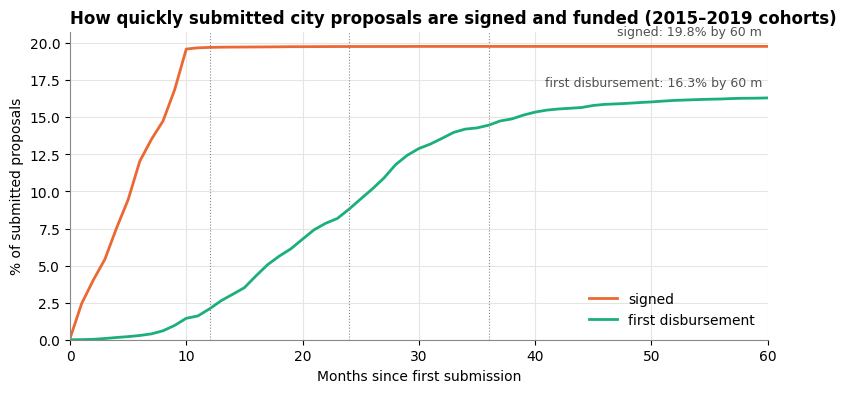

,signed,first disbursement
6 m,12.0,0.3
12 m,19.7,2.1
24 m,19.8,8.8
36 m,19.8,14.5
60 m,19.8,16.3


In [35]:
# Fit 2 (chart): cumulative share signed / disbursed by months since submission, cohorts 2015-2019 (fully observed)
mature = city.loc[city["submission_year"].between(2015, 2019)]
grid = np.arange(0, 61, 1)
curves = {
    "signed": (mature["dt_assinatura"] - mature["dt_first_submitted"]).dt.days / 30.44,
    "first disbursement": (mature["dt_first_desembolso"] - mature["dt_first_submitted"]).dt.days / 30.44,
}
fig, ax = plt.subplots(figsize=(9, 4))
for (label, t), colour in zip(curves.items(), SERIES[1:]):
    share = [(t <= m).mean() * 100 for m in grid]
    ax.plot(grid, share, color=colour, linewidth=2, label=label)
    ax.annotate(f"{label}: {share[-1]:.1f}% by 60 m", (grid[-1], share[-1]), xytext=(-4, 8), textcoords="offset points",
                ha="right", fontsize=9, color="#52514e")
for m in (12, 24, 36):
    ax.axvline(m, color="#8a8984", linewidth=0.8, linestyle=":")
ax.set(title="How quickly submitted city proposals are signed and funded (2015–2019 cohorts)",
       xlabel="Months since first submission", ylabel="% of submitted proposals", xlim=(0, 60), ylim=(0, None))
ax.legend(frameon=False, loc="lower right")
plt.show()
pd.DataFrame({label: {f"{m} m": round((t <= m).mean() * 100, 1) for m in (6, 12, 24, 36, 60)} for label, t in curves.items()})

In [36]:
# Fit 2 (window): share of each stage's eventual events that happen within 12/24/36 months, 2015-2019 cohorts
eventual = {label: t.dropna() for label, t in curves.items()}
pd.DataFrame({label: {f"within {m} m": round((t <= m).mean() * 100, 1) for m in (12, 24, 36)} for label, t in eventual.items()})

,signed,first disbursement
within 12 m,99.6,12.6
within 24 m,99.9,53.3
within 36 m,100.0,87.6


In [37]:
# Fit 3: need must-have fields (search.yaml) present on submitted city proposals
must_have = pd.Series({
    "native_record_id (id_proposta / nr_convenio)": city["id_proposta"].notna().mean(),
    "recipient name + type": (city["nome_proponente"].notna() & city["natureza_juridica"].notna()).mean(),
    "recipient_geography (UF + IBGE)": (city["uf"].notna() & city["cod_ibge"].notna()).mean(),
    "funder_or_programme": city["nome_programa"].notna().mean(),
    "instrument (modalidade)": city["modalidade"].notna().mean(),
    "amount requested (federal share)": city["vl_repasse_prop_cent"].notna().mean(),
    "stage + date: submitted": city["dt_first_submitted"].notna().mean(),
    "stage + date: signed (of signed)": city.loc[city["is_signed"], "dt_assinatura"].notna().mean(),
    "stage + date: disbursed (of disbursed)": city.loc[city["is_disbursed"], "dt_first_desembolso"].notna().mean(),
    "project_description (objeto)": city["objeto_proposta"].notna().mean(),
}, name="% present").mul(100).round(2)
must_have.to_frame()

,% present
native_record_id (id_proposta / nr_convenio),100.0
recipient name + type,100.0
recipient_geography (UF + IBGE),100.0
funder_or_programme,100.0
instrument (modalidade),100.0
amount requested (federal share),100.0
stage + date: submitted,100.0
stage + date: signed (of signed),100.0
stage + date: disbursed (of disbursed),100.0
project_description (objeto),100.0


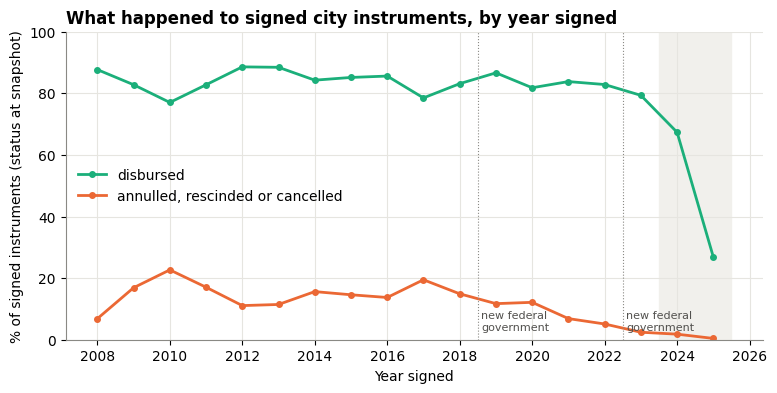

,signed,disbursed,annulled_rescinded_cancelled
sign_year,,,
2008,878,87.7,6.8
2009,16429,82.8,16.9
2010,15476,77.0,22.7
2011,8604,82.8,17.0
2012,6599,88.6,11.1
2013,12319,88.4,11.4
2014,8258,84.3,15.6
2015,6002,85.2,14.6
2016,9329,85.6,13.7


In [38]:
# Fit 4: signed city instruments by signature year: disbursed, and later annulled or rescinded
signed_city = proposals.loc[proposals["is_city_applicant"] & proposals["is_signed"], ["id_proposta", "dt_assinatura", "sit_convenio", "is_disbursed"]].copy()
signed_city["sign_year"] = signed_city["dt_assinatura"].dt.year
signed_city["ended_unexecuted"] = signed_city["sit_convenio"].isin(["Convênio Anulado", "Convênio Rescindido", "Cancelado"])
by_year = signed_city.groupby("sign_year").agg(signed=("id_proposta", "size"), disbursed=("is_disbursed", "mean"),
                                               annulled_rescinded_cancelled=("ended_unexecuted", "mean")).loc[2008:2025]
fig, ax = plt.subplots(figsize=(9, 4))
for col, colour, label in [("disbursed", SERIES[2], "disbursed"), ("annulled_rescinded_cancelled", SERIES[1], "annulled, rescinded or cancelled")]:
    ax.plot(by_year.index, by_year[col] * 100, color=colour, linewidth=2, marker="o", markersize=4, label=label)
for yr, lab in [(2019, "new federal\ngovernment"), (2023, "new federal\ngovernment")]:
    ax.axvline(yr - 0.5, color="#8a8984", linewidth=0.8, linestyle=":")
    ax.text(yr - 0.4, 3, lab, fontsize=8, color="#52514e")
ax.set(title="What happened to signed city instruments, by year signed", xlabel="Year signed",
       ylabel="% of signed instruments (status at snapshot)", ylim=(0, 100))
ax.axvspan(2023.5, 2025.5, color="#f1f0ec", zorder=0)
ax.xaxis.set_major_locator(plt.MultipleLocator(2))
ax.legend(frameon=False, loc="center left")
plt.show()
by_year.assign(disbursed=(by_year["disbursed"] * 100).round(1),
               annulled_rescinded_cancelled=(by_year["annulled_rescinded_cancelled"] * 100).round(1))

In [39]:
# Fit 4b (need test): do Novo PAC formalisation proposals trace to signed and paid instruments?
pac = proposals.loc[proposals["subtipo_proposta"].eq("NOVO PAC - FORMALIZAÇÃO")]
pd.Series({"proposals": len(pac), "submitted": pac["is_submitted"].sum(), "approved": pac["is_approved"].sum(),
           "with agreement": pac["has_agreement"].sum(), "signed": pac["is_signed"].sum(), "net committed": pac["is_net_committed"].sum(),
           "disbursed": pac["is_disbursed"].sum(), "paid onward": pac["is_paid"].sum()}, name="Novo PAC formalização").to_frame()

,Novo PAC formalização
proposals,5323
submitted,5146
approved,5193
with agreement,5197
signed,5161
net committed,5052
disbursed,2631
paid onward,1329


### What the proposals are for

The fit cells above treat every proposal alike. These cells look at content: which ministries the money runs through, and how much of the portfolio touches adaptation themes. The theme screen is a first-pass search, not a classification. It combines two signals: the object text (what the applicant says the project is) and the programme name (which federal line funds it). A match on either is a candidate for Phase C adjudication, never a label.

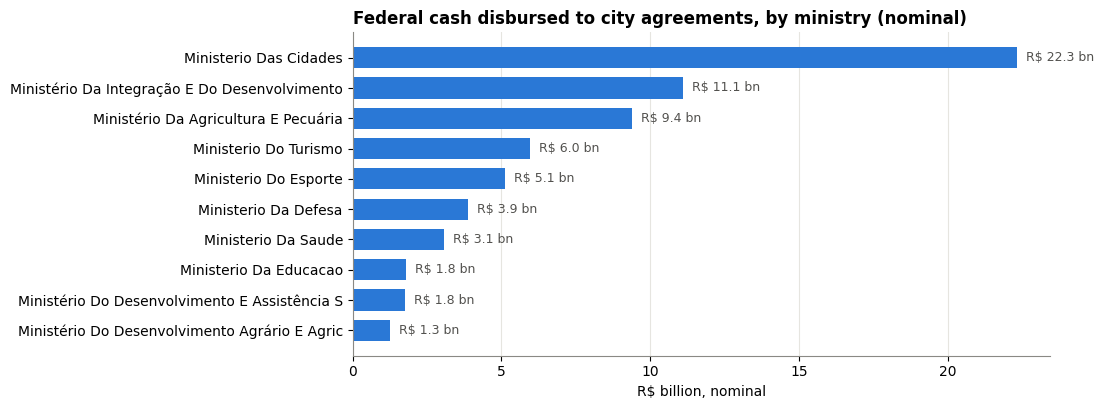

,submitted,signed,disbursed_brl_bn,share_of_submitted_%,share_of_disbursed_%
orgao_superior,,,,,
MINISTERIO DAS CIDADES,79244,44026,22.3,10.0,32.8
MINISTÉRIO DA INTEGRAÇÃO E DO DESENVOLVIMENTO REGIONAL,83662,16906,11.1,10.6,16.3
MINISTÉRIO DA AGRICULTURA E PECUÁRIA,224921,30792,9.4,28.4,13.8
MINISTERIO DO TURISMO,134744,15742,6.0,17.0,8.8
MINISTERIO DO ESPORTE,100640,16927,5.1,12.7,7.5
MINISTERIO DA DEFESA,6127,4773,3.9,0.8,5.7
MINISTERIO DA SAUDE,53242,8984,3.1,6.7,4.5
MINISTERIO DA EDUCACAO,3748,2403,1.8,0.5,2.6
"MINISTÉRIO DO DESENVOLVIMENTO E ASSISTÊNCIA SOCIAL, FAMÍLIA E COMBATE FOME",25067,5511,1.8,3.2,2.6


In [40]:
# Content 1: which ministries submitted city proposals go through, by count and by federal cash disbursed
ministry = (city.join(proposals.loc[city.index, ["orgao_superior", "vl_desembolso_net_cent"]])
            .groupby("orgao_superior")
            .agg(submitted=("id_proposta", "size"), signed=("is_signed", "sum"),
                 disbursed_brl_bn=("vl_desembolso_net_cent", lambda s: s.sum() / 1e11)))
ministry["share_of_submitted_%"] = ministry["submitted"] / ministry["submitted"].sum() * 100
ministry["share_of_disbursed_%"] = ministry["disbursed_brl_bn"] / ministry["disbursed_brl_bn"].sum() * 100
top = ministry.sort_values("disbursed_brl_bn", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(top.index.str.title().str.slice(0, 45)[::-1], top["disbursed_brl_bn"][::-1], color=SERIES[0], height=0.7)
for y, v in enumerate(top["disbursed_brl_bn"][::-1]):
    ax.text(v + 0.3, y, f"R$ {v:.1f} bn", va="center", fontsize=9, color="#52514e")
ax.grid(axis="y", visible=False)
ax.set(title="Federal cash disbursed to city agreements, by ministry (nominal)", xlabel="R$ billion, nominal")
plt.show()
top.round(1)

In [41]:
# Content 2: theme screen. Accent-stripped, lower-case text; a theme matches on the object text, the programme name, or both.
def plain(s):
    return s.fillna("").str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii").str.lower()

content = proposals.loc[city.index, ["id_proposta", "objeto_proposta", "nome_programa", "orgao_superior", "is_signed", "is_disbursed",
                                     "vl_repasse_conv_cent", "vl_contrapartida_conv_cent", "vl_global_conv_cent",
                                     "vl_desembolso_net_cent", "dt_assinatura", "dt_first_desembolso"]].copy()
obj, prog = plain(content["objeto_proposta"]), plain(content["nome_programa"])

OBJECT_TERMS = {   # what the applicant says the project is
    "drainage and stormwater": r"drenagem|aguas pluviais|galerias? pluvia|macrodrenagem|microdrenagem|canalizac",
    "slope stabilisation": r"encosta|deslizament|muro de arrimo|estabilizacao de talude|contencao de (?:encosta|talude|margem)",
    "flood control": r"enchente|inundac|alagament|controle de cheias|piscinao|piscinoes|reservatorio de (?:amortecimento|detencao|retencao)",   # not "piscin": matches swimming pools
    "water supply and drought": r"abastecimento de agua|adutora|cisterna|pocos? (?:tubular|artesiano)|dessaliniz|(?:construcao|recuperacao|ampliacao) de (?:acude|barragem|barreiro|pequenas barragens)|barragens? subterranea|seguranca hidrica",   # a bare "acude" matches tourism works at reservoirs
    "erosion control": r"erosao|erosiv|vocoroca|conservacao do solo",
    "disaster risk and response": r"defesa civil|desastre|calamidade|situacao de emergencia|estado de emergencia|area de risco",
    "green and nature-based": r"arboriza|reflorest|mata ciliar|nascente|parque linear|revegeta|area degradada|recuperacao ambiental",
    "sanitation and sewage (context)": r"esgot|saneamento|residuos solidos|aterro sanitario",
    "road paving (context)": r"paviment|recapeamento|calcament|asfalt|paralelepiped|bloquete",
}
PROGRAMME_TERMS = {   # which federal line funds it
    "drainage and stormwater": r"drenagem|aguas pluviais",
    "slope stabilisation": r"encosta",
    "flood control": r"cheias|inundac",
    "water supply and drought": r"abastecimento de agua|seguranca hidrica|agua para todos|cisterna",
    "erosion control": r"controle de erosao",
    "disaster risk and response": r"desastre|gestao de riscos|defesa civil",
}
for theme, rx in OBJECT_TERMS.items():
    content[f"obj:{theme}"] = obj.str.contains(rx, regex=True)
for theme, rx in PROGRAMME_TERMS.items():
    content[f"prog:{theme}"] = prog.str.contains(rx, regex=True)
# Paving projects routinely list kerbs, gutters and "drenagem" as complementary works: separate them out
content["paving_with_drainage"] = content["obj:road paving (context)"] & content["obj:drainage and stormwater"]

rows = {}
for theme in OBJECT_TERMS:
    o = content[f"obj:{theme}"]
    p = content.get(f"prog:{theme}", pd.Series(False, index=content.index))
    hit = (o & ~content["paving_with_drainage"]) | p if theme == "drainage and stormwater" else o | p
    m = content[hit]
    rows[theme] = {"proposals": int(hit.sum()), "object text only": int((o & ~p & hit).sum()), "programme only": int((p & ~o).sum()),
                   "both": int((o & p).sum()), "signed %": m["is_signed"].mean() * 100, "disbursed %": m["is_disbursed"].mean() * 100,
                   "disbursed R$ bn": m["vl_desembolso_net_cent"].sum() / 1e11}
    content[f"theme:{theme}"] = hit
themes = pd.DataFrame(rows).T
themes.loc["paving that mentions drainage (context)"] = {"proposals": int(content["paving_with_drainage"].sum()),
    "signed %": content.loc[content["paving_with_drainage"], "is_signed"].mean() * 100,
    "disbursed %": content.loc[content["paving_with_drainage"], "is_disbursed"].mean() * 100,
    "disbursed R$ bn": content.loc[content["paving_with_drainage"], "vl_desembolso_net_cent"].sum() / 1e11}
ADAPTATION = [t for t in OBJECT_TERMS if "(context)" not in t]
any_adapt = content[[f"theme:{t}" for t in ADAPTATION]].any(axis=1)
print(f"submitted city proposals matching any adaptation theme: {any_adapt.sum():,} ({any_adapt.mean():.1%})")
themes.astype(float).round(1)

submitted city proposals matching any adaptation theme: 33,501 (4.2%)


,proposals,object text only,programme only,both,signed %,disbursed %,disbursed R$ bn
drainage and stormwater,6497.0,4307.0,661.0,1529.0,12.8,6.6,0.6
slope stabilisation,1158.0,967.0,13.0,178.0,29.6,12.7,0.2
flood control,406.0,406.0,0.0,0.0,16.5,6.9,0.1
water supply and drought,18283.0,12148.0,980.0,5155.0,17.3,7.1,1.5
erosion control,1513.0,481.0,975.0,57.0,4.9,3.0,0.1
disaster risk and response,9148.0,268.0,8251.0,629.0,8.8,3.5,0.5
green and nature-based,2227.0,2227.0,0.0,0.0,7.1,5.2,0.1
sanitation and sewage (context),19663.0,19663.0,0.0,0.0,11.2,5.6,0.8
road paving (context),130521.0,130521.0,0.0,0.0,34.8,29.6,27.4
paving that mentions drainage (context),18643.0,NaN,NaN,NaN,42.8,36.1,6.4


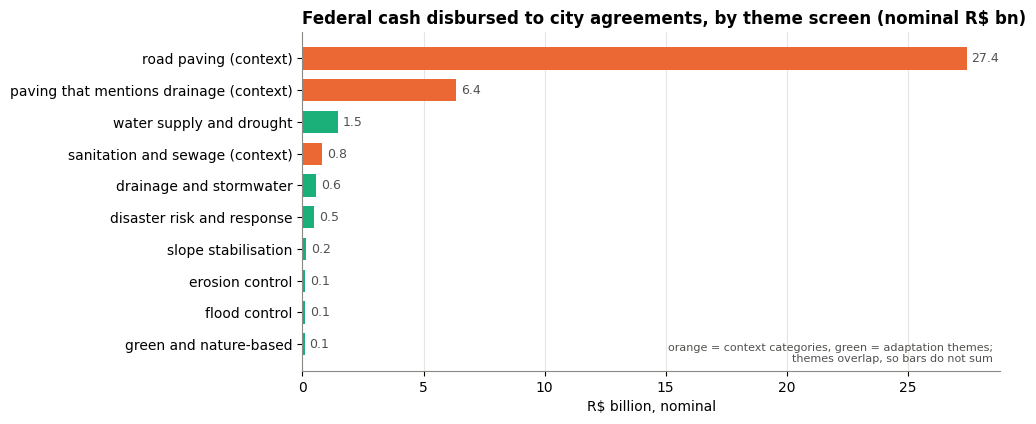

In [42]:
# Content 2 (chart): adaptation themes against the two biggest context categories, by federal cash disbursed
plot = themes["disbursed R$ bn"].astype(float).sort_values()
colours = [SERIES[1] if "(context)" in t else SERIES[2] for t in plot.index]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(plot.index, plot.values, color=colours, height=0.7)
for y, v in enumerate(plot.values):
    ax.text(v + 0.2, y, f"{v:.1f}", va="center", fontsize=9, color="#52514e")
ax.grid(axis="y", visible=False)
ax.set(title="Federal cash disbursed to city agreements, by theme screen (nominal R$ bn)", xlabel="R$ billion, nominal")
ax.text(0.99, 0.02, "orange = context categories, green = adaptation themes;\nthemes overlap, so bars do not sum",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="#52514e")
plt.show()

In [43]:
# Content 3: precision check. Eight random matches per adaptation theme (fixed seed) to read by eye; the precision
# judgement from this read goes in the Findings, not in code.
samples = pd.concat([content.loc[content[f"theme:{t}"], ["objeto_proposta", "nome_programa"]].sample(8, random_state=7).assign(theme=t)
                     for t in ADAPTATION])
samples.assign(objeto_proposta=samples["objeto_proposta"].str.slice(0, 110), nome_programa=samples["nome_programa"].str.slice(0, 60)).set_index("theme")

,objeto_proposta,nome_programa
theme,,
drainage and stormwater,Revitalização do Teatro São Francisco de Assis...,APOIO A PROJETOS DE INFRAESTRUTURA TURÍSTICA -...
drainage and stormwater,"ADEQUAÇÃO DE ESTRADAS VICINAIS,INCLUINDO TERRA...",Fomento ao Setor Agropecuario - Investimento
drainage and stormwater,IMPLANTAÇÃO DE GALERIAS DE ÁGUAS PLUVIAIS NO M...,CENTRO-OESTE - PREVENÇÃO E PREPARAÇÃO PARA DES...
drainage and stormwater,Construção de Pontes de Concreto Armado e Aço ...,PROGRAMA CALHA NORTE
drainage and stormwater,SANEAMENTO EM ÁREAS URBANAS E RURAIS,2068 - Saneamento Básico (3883 - Serviços de D...
drainage and stormwater,Execução de drenagem e Galerias Pluviais de Go...,2068 - Saneamento Básico (Melhorias Sanitárias...
drainage and stormwater,Apoio financeiro para a instalação de infraest...,PROGRAMA DE APOIO A PROJETOS DE INFRAESTRUTURA...
drainage and stormwater,Aquisição de máquina(s) autopropulsada(s) para...,Fomento ao Setor Agropecuário - Investimento e...
slope stabilisation,Pavimentação de Pedras Poliédricas e a constru...,Apoio a Projetos de Infraestrutura Turística -...


In [44]:
# Content 4: benchmark values for funded (disbursed) city agreements, by theme. Nominal BRL, no deflator.
def benchmarks(m):
    months_to_cash = (m["dt_first_desembolso"] - m["dt_assinatura"]).dt.days / 30.44
    counterpart = m["vl_contrapartida_conv_cent"] / m["vl_global_conv_cent"]
    return pd.Series({
        "funded agreements": len(m),
        "federal share, median R$ k": m["vl_repasse_conv_cent"].median() / 1e5,
        "federal share, p25 R$ k": m["vl_repasse_conv_cent"].quantile(0.25) / 1e5,
        "federal share, p75 R$ k": m["vl_repasse_conv_cent"].quantile(0.75) / 1e5,
        "counterpart share, median %": counterpart.median() * 100,
        "signature to first cash, median months": months_to_cash.median(),
    })
funded = content.loc[content["is_disbursed"]]
bench = pd.DataFrame({t: benchmarks(funded.loc[funded[f"theme:{t}"]]) for t in ADAPTATION + ["road paving (context)"]}).T
bench.loc["all funded city agreements"] = benchmarks(funded)
bench.round(1)

,funded agreements,"federal share, median R$ k","federal share, p25 R$ k","federal share, p75 R$ k","counterpart share, median %","signature to first cash, median months"
drainage and stormwater,426.0,606.7,286.7,1882.6,2.9,18.9
slope stabilisation,147.0,1176.4,405.1,4955.0,2.2,17.6
flood control,28.0,1093.8,464.6,7274.0,3.8,18.1
water supply and drought,1292.0,513.4,285.0,1500.0,1.0,22.7
erosion control,46.0,795.1,500.0,1199.7,3.0,21.0
disaster risk and response,319.0,999.7,390.0,4687.5,3.0,12.9
green and nature-based,116.0,484.3,245.8,807.0,3.7,19.4
road paving (context),38579.0,344.8,245.8,603.8,2.9,18.4
all funded city agreements,118545.0,295.3,236.0,528.4,3.2,17.1


## Findings

Extraction reproduced the Step 2 profile exactly on row counts, keys and joins, and every stage total reconciles to the centavo with the raw files. The notebook needs about 6 GB of memory at peak and runs in roughly four minutes.

Six data facts flowed back into the README parsing notes and warnings. First, counting in exact centavos changes the stage-order exceptions from the profiled 12,511 / 7,210 / 251 to 12,474 committed-but-unsigned, 7,211 disbursed-without-net-commitment and 246 paid-without-disbursement: floating-point residues around 1e-10 had been read as positive nets, and payments back to the recipient no longer count as onward payment. Second, the 32 "negative committed values" split into 16 residues and 16 genuine negative totals. Third, `COD_HISTORICO_SIT = -1` simply marks four labels that have no numeric code. Fourth, programme rows repeat per state, applicant legal nature and modality, and only the modality varies within an ID. Fifth, disbursement events reconcile exactly with each agreement's own disbursed total, but commitment totals differ from the event sums for 7,833 agreements, so commitment is taken from events. Sixth, submission events in the status history only begin in April 2010, so the roughly 132,000 city proposals from 2008–2009 cannot enter submission cohorts.

For fit, every must-have field in the need is present for all 791,928 submitted city proposals. The minimum follow-up window, left open in the methodology, is now answerable. Almost all signatures (99.6%) happen within 12 months of submission. First disbursement is slower: 53% of eventual first disbursements arrive within 24 months and 88% within 36 months. Signature comparisons therefore need 12 months of follow-up, and funding comparisons need 36, which means cohorts from 2023 onward are not yet comparable for disbursement. In the fully observed 2015–2019 cohorts, about one in five submitted city proposals was signed and about one in six received federal cash.

The government-transition chart does not show a transition effect by itself. The share of signed instruments later annulled, rescinded or cancelled falls steadily for recent signing years, which is mostly follow-up time: cancellations accumulate years after signature. Any transition comparison has to hold follow-up constant. The need's Novo PAC tracing test works through native identifiers: 5,161 of 5,323 formalisation proposals are signed, 2,631 have received a disbursement and 1,329 show onward payments. Several Novo PAC proposals have approval events without a submission event, which is consistent with a formalisation route that skips the usual application step.
What the proposals are for is the main limit on adaptation use. By count, submitted city proposals are led by agriculture (28%), tourism (17%) and sport (13%); by federal cash, the Ministry of Cities takes a third of the R$68 billion disbursed to cities and the regional development ministry a sixth. Road paving alone is 16.5% of submitted proposals and R$27.4 billion disbursed. The theme screen finds 33,501 proposals (4.2%) touching an adaptation theme. Water supply and drought is the largest (18,283 proposals, R$1.5 billion disbursed) and the cleanest match: all eight sampled rows are water-supply works. Slope and flood matches are mostly right (about five in eight). Drainage and disaster-risk matches are noisy (about three in eight): object text mentions drainage in theatre and rural-road works, and the prevention programmes (1027, 2040) also fund rural roads, bridges and fords. Paving projects that mention drainage (18,643 proposals, R$6.4 billion) are kept apart because the drainage is usually kerbs and gutters. These precision figures are one reviewer's read of eight rows per theme (inferred), and every match is a candidate for Phase C adjudication, not a label. Funded agreements in adaptation themes are larger than the typical city agreement (median federal share R$0.5 to 1.2 million against R$0.3 million overall), carry a small counterpart (1 to 4%) and take 13 to 23 months from signature to first cash.
